## Ambiente e diretórios

Execute na ordem. A raiz é a pasta que contém dados/ e notebooks/. Se faltar um pacote, use o comando do README no kernel selecionado.

In [1]:
from pathlib import Path
from itertools import product
from zipfile import ZipFile
from urllib.request import urlretrieve
import re
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

raiz = Path.cwd().resolve()
if raiz.name == 'notebooks':
    raiz = raiz.parent
original = raiz / 'dados/original'
tabelas = raiz / 'resultados/tabelas'
figuras = raiz / 'resultados/graficos'
processados = raiz / 'dados/processados'
for pasta in [original, tabelas, figuras, processados]:
    pasta.mkdir(parents=True, exist_ok=True)
csv = original / 'PENSE2024_MICRODADOS.csv'
xlsx = original / 'dicionario.xlsx'
semente = 42
def salvar(tab, nome):
    tab.to_csv(tabelas / (nome + '.csv'), index=False, encoding='utf-8-sig')
def figura(fig, nome):
    fig.text(.01, .005, 'Fonte: IBGE, PeNSE 2024. Cálculos amostrais sem ponderação.', fontsize=8)
    fig.tight_layout(rect=[0,.04,1,1])
    fig.savefig(figuras / (nome + '.png'), dpi=175, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Arquivos oficiais

Reaproveita arquivos locais. Na primeira execução, baixa apenas os pacotes que faltam e extrai o CSV e o dicionário.

In [2]:
url = 'https://ftp.ibge.gov.br/pense/2024/microdados/'
for destino, pacote, extensao in [(csv,'Dados.zip','.csv'),(xlsx,'Documentacao.zip','.xlsx')]:
    if destino.exists():
        continue
    arquivo = original / pacote
    if not arquivo.exists():
        parcial = arquivo.with_suffix('.part')
        urlretrieve(url + pacote, parcial)
        parcial.replace(arquivo)
    with ZipFile(arquivo) as z:
        membro, = [n for n in z.namelist() if n.lower().endswith(extensao)]
        with z.open(membro) as entrada, destino.with_suffix('.part').open('wb') as saida:
            shutil.copyfileobj(entrada, saida)
        destino.with_suffix('.part').replace(destino)

## Dicionário e leitura seletiva

Confere nomes no CSV e extrai todos os códigos de resposta do dicionário oficial. Os quatro campos de identificação permitem verificar duplicatas.

In [3]:
nomes = {'B01021B':'Série','B01026A2':'Plano após o EM','B01006':'Mora com mãe','B01007':'Mora com pai','B13006':'Falta por saúde','B09002':'Insegurança na escola','B12005':'Tristeza','B07001':'Falta sem permissão','B09001':'Insegurança no trajeto'}
chave = ['ESTRATO_EXP','ESCOLA','TURMA','ALUNO']
livro = pd.read_excel(xlsx).set_index('Nome da Variável').loc[list(nomes)]
cab = pd.read_csv(csv, nrows=0).columns
raw = pd.read_csv(csv, usecols=chave + ['IND_EXPANSAO'] + list(nomes))
print('Dimensão original:', len(raw), '×', len(cab))
print(raw.dtypes)
if raw[chave].isna().any().any() or raw.duplicated(chave).any():
    raise ValueError('Verifique a chave amostral antes de continuar.')
dom = raw.loc[raw.IND_EXPANSAO.eq(1),list(nomes)].copy()
dom.index.name = 'linha_csv_indice_zero'
dic = {}
tipos_especiais = {'Pulo','Abandono','Sem resposta'}
linhas = []
for v, r in livro.iterrows():
    pares = {}
    for linha in r['Categoria'].splitlines():
        m = re.fullmatch(r'\s*(-?\d+)\s*-\s*(.+?)\s*', linha)
        if not m:
            raise ValueError((v,linha))
        pares[int(m[1])] = m[2]
    dic[v] = pares
    for codigo, rotulo in pares.items():
        linhas.append([v, r['Descrição da Variável'], codigo, rotulo])
salvar(pd.DataFrame(linhas, columns=['variavel','pergunta','codigo','rotulo']), 'dicionario_selecao')
print('Domínio IND_EXPANSAO=1:', len(dom), '| Fora do domínio:',len(raw)-len(dom))

Dimensão original: 153870 × 430
IND_EXPANSAO      int64
ESTRATO_EXP       int64
ESCOLA            int64
TURMA             int64
ALUNO             int64
B01021B         float64
B01026A2        float64
B01006          float64
B01007          float64
B07001          float64
B12005          float64
B09001          float64
B09002          float64
B13006          float64
dtype: object
Domínio IND_EXPANSAO=1: 148736 | Fora do domínio: 5134


## Limpeza e frequências

Preserva motivos de ausência na auditoria, inclusive células vazias. Para cada variável, o percentual válido usa apenas as respostas substantivas.

In [4]:
limpa = pd.DataFrame(index=dom.index)
auditoria = []
qualidade = []
for v, mapa in dic.items():
    validos = [c for c,r in mapa.items() if r not in tipos_especiais]
    desconhecidos = set(dom[v].dropna().unique()) - mapa.keys()
    if desconhecidos or any(c < 0 for c in validos):
        raise ValueError(f'Revisar códigos em {v}: {desconhecidos} / {validos}')
    limpa[v] = dom[v].where(dom[v].isin(validos)).astype('Int8')
    nval = limpa[v].count()
    for c,r in list(mapa.items()) + [(None,'Célula vazia')]:
        n = int(dom[v].eq(c).sum()) if c is not None else int(dom[v].isna().sum())
        auditoria.append([v,c,r,n,100*n/len(dom),100*n/nval if c in validos and nval else np.nan])
    qualidade.append([v,nval,100*(1-nval/len(dom)),limpa[v].value_counts(normalize=True).max()*100])
freq = pd.DataFrame(auditoria, columns=['variavel','codigo','categoria','n','pct_dominio','pct_validos'])
qual = pd.DataFrame(qualidade,columns=['variavel','n_validos','pct_ausencia','pct_moda'])
salvar(freq,'frequencias')
salvar(qual,'qualidade')
limpa.to_csv(processados/'base_limpa.csv.gz')
print(qual.round(2).to_string(index=False))
print('Perfis repetidos nas nove respostas (mantidos):',limpa.duplicated().sum())

variavel  n_validos  pct_ausencia  pct_moda
 B01021B     148677          0.04     19.43
B01026A2     148596          0.09     62.06
  B01006     148670          0.04     89.97
  B01007     148614          0.08     63.50
  B13006     147065          1.12     36.32
  B09002     147144          1.07     87.80
  B12005     147956          0.52     36.43
  B07001     148250          0.33     81.13
  B09001     147233          1.01     89.54
Perfis repetidos nas nove respostas (mantidos): 123203


## Exploração

Compara faltas por insegurança na escola segundo frequência de tristeza. Os números nas barras usam o total de pares válidos em cada categoria.

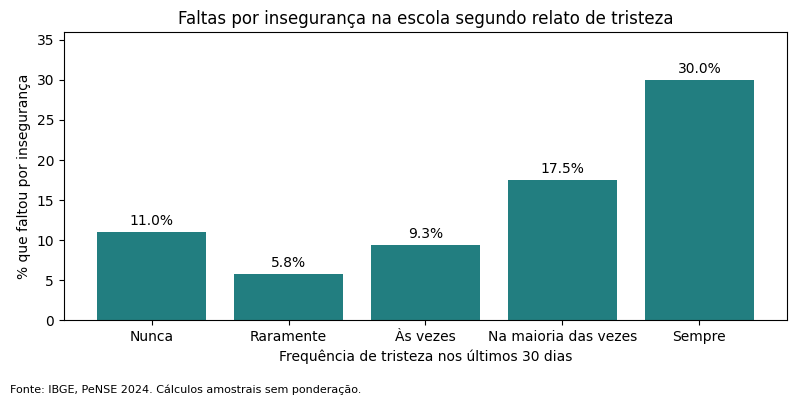

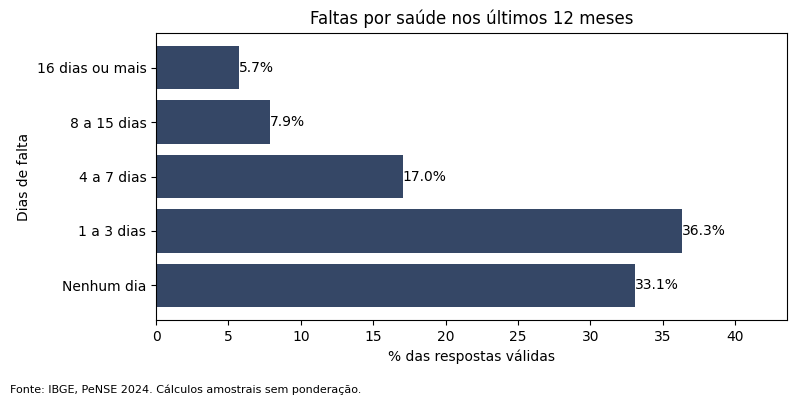

In [5]:
s = 'B12005'
e = 'B09002'
pares = limpa[[s,e]].dropna()
cruz = pares.groupby(s)[e].agg(n='size',faltaram=lambda x:x.gt(1).sum()).reset_index()
cruz['pct'] = 100*cruz.faltaram/cruz.n
cruz['categoria'] = cruz[s].map(dic[s])
salvar(cruz,'tristeza_inseguranca')
fig,ax = plt.subplots(figsize=(8,4))
b=ax.bar(cruz.categoria,cruz.pct,color='#227e80')
ax.bar_label(b,fmt='%.1f%%',padding=3)
ax.set(xlabel='Frequência de tristeza nos últimos 30 dias',ylabel='% que faltou por insegurança',title='Faltas por insegurança na escola segundo relato de tristeza',ylim=(0,1.2*cruz.pct.max()))
figura(fig,'tristeza_inseguranca')
fig,ax=plt.subplots(figsize=(8,4))
saude=freq.query("variavel=='B13006' and pct_validos==pct_validos").copy()
saude['faixa']=['Nenhum dia' if c==1 else dic['B13006'][c] for c in saude.codigo]
b=ax.barh(saude.faixa,saude.pct_validos,color='#354766')
ax.bar_label(b,fmt='%.1f%%')
ax.set(xlabel='% das respostas válidas',ylabel='Dias de falta',title='Faltas por saúde nos últimos 12 meses',xlim=(0,1.2*saude.pct_validos.max()))
figura(fig,'distribuicao_saude')

## Perfis para K-Means

Cinco itens ordinais, escalados pela amplitude teórica de cada pergunta. Um passo representa uma categoria, sem equivalência em dias. Série, família e planos entram apenas na descrição dos grupos. Cinco dimensões dispensam PCA para ajuste.

In [6]:
ativas=['B13006','B09002','B09001','B07001','B12005']
cc=limpa[ativas].dropna()
def escalar(dados):
    x=dados.astype(float)
    for v in ativas:
        dominio=[k for k,r in dic[v].items() if r not in tipos_especiais]
        x[v]=(x[v]-min(dominio))/(max(dominio)-min(dominio))
    return x
X=escalar(cc)
X.to_csv(processados/'base_cluster_escalada.csv.gz')
# Comprimir padrões iguais com suas multiplicidades preserva a função objetivo exata.
U, inversa, contagens=np.unique(X.to_numpy(), axis=0, return_inverse=True, return_counts=True)
inversa=inversa.reshape(-1)
rng=np.random.default_rng(semente)
amostra=rng.choice(len(X),size=min(2000,len(X)),replace=False)
print('Casos completos:',len(X),'| Perfis únicos:',len(U),'| Excluídos:',len(dom)-len(X))

Casos completos: 146099 | Perfis únicos: 2996 | Excluídos: 2637


## Comparação de K

Ajuste com todos os casos completos. A mesma amostra aleatória simples de até 2.000 alunos aproxima a Silhouette para limitar memória e tempo. Escolha pela maior Silhouette, com menor K em empate. O cotovelo complementa a decisão.

 k   inercia  silhouette  queda_relativa_pct
 1 38172.382         NaN                 NaN
 2 29317.692       0.291              23.197
 3 23661.961       0.294              19.291
 4 18770.620       0.326              20.672
 5 16942.952       0.336               9.737
 6 15234.068       0.320              10.086
 7 13790.969       0.324               9.473
 8 12697.028       0.324               7.932


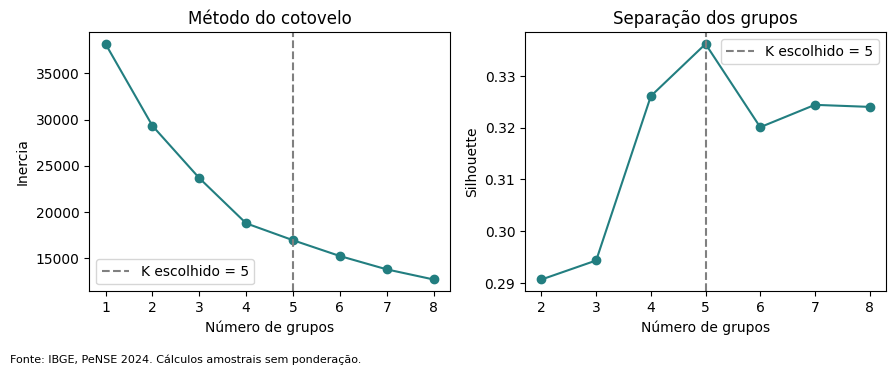

In [7]:
avaliacao=[]
modelos={}
with threadpool_limits(limits=1):
    for k in range(1,min(9,len(U)+1)):
        modelo=KMeans(n_clusters=k,n_init=20,random_state=semente,algorithm='lloyd')
        modelo.fit(U,sample_weight=contagens)
        y= modelo.labels_[inversa[amostra]]
        sil=silhouette_score(X.iloc[amostra],y) if 1<len(set(y))<len(y) else np.nan
        avaliacao.append([k,modelo.inertia_,sil])
        modelos[k]=modelo
av=pd.DataFrame(avaliacao,columns=['k','inercia','silhouette'])
av['queda_relativa_pct']=-100*av.inercia.pct_change()
salvar(av,'avaliacao_k')
k=int(av.loc[av.silhouette.idxmax(),'k'])
grupo=pd.Series(modelos[k].labels_[inversa]+1,index=X.index,name='grupo')
limpa.join(grupo.astype('Int8')).to_csv(processados/'base_com_grupos.csv.gz')
print(av.round(3).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(9,3.7))
for ax,col,titulo in zip(axs,['inercia','silhouette'],['Método do cotovelo','Separação dos grupos']):
    ax.plot(av.k,av[col],'o-',color='#227e80')
    ax.axvline(k,color='gray',linestyle='--',label=f'K escolhido = {k}')
    ax.set(xlabel='Número de grupos',ylabel=col.capitalize(),title=titulo)
    ax.legend()
figura(fig,'escolha_k')

## Caracterização

A média do escore 0–1 permite comparar os centros. As frequências por grupo recuperam as categorias originais. A fração de variância entre grupos mede separação descritiva nas variáveis usadas no ajuste.

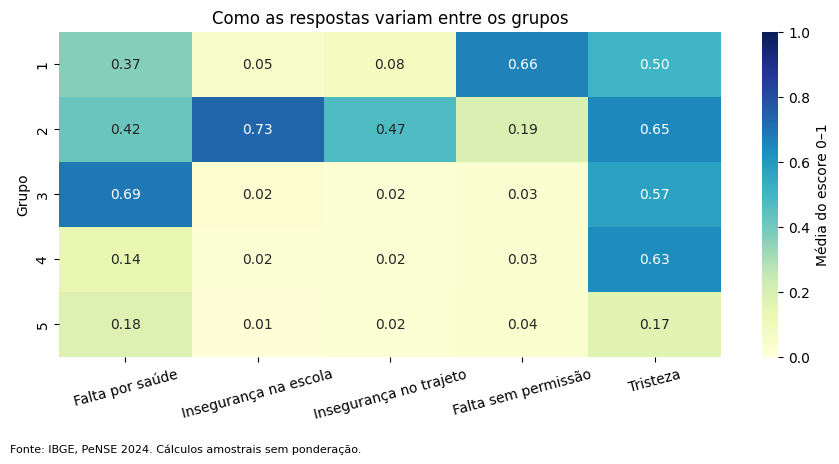

       B13006  B09002  B09001  B07001  B12005      n
grupo                                               
1       0.366   0.052   0.077   0.661   0.504   7064
2       0.419   0.732   0.475   0.190   0.647   8308
3       0.686   0.025   0.023   0.035   0.574  31101
4       0.136   0.020   0.023   0.032   0.633  57055
5       0.177   0.012   0.022   0.035   0.170  42571


In [8]:
centros=X.groupby(grupo).mean()
tamanhos=grupo.value_counts().sort_index().rename('n')
salvar(centros.join(tamanhos).reset_index(),'centros')
diferenca=1-X.sub(X.groupby(grupo).transform('mean')).pow(2).sum()/X.sub(X.mean()).pow(2).sum()
salvar(diferenca.sort_values(ascending=False).rename('fracao_entre_grupos').rename_axis('variavel').reset_index(),'separacao')
perfis=[]
for v in nomes:
    tab=pd.crosstab(grupo,limpa[v]).rename_axis(index='grupo',columns='codigo')
    p=tab.stack().rename('n').reset_index()
    p['pct_validos_grupo']=100*p.n/p.groupby('grupo').n.transform('sum')
    p['categoria']=p.codigo.map(dic[v])
    p['variavel']=v
    perfis.append(p)
salvar(pd.concat(perfis),'perfis')
fig,ax=plt.subplots(figsize=(9,4.6))
sns.heatmap(centros.rename(columns=nomes),vmin=0,vmax=1,annot=True,fmt='.2f',cmap='YlGnBu',ax=ax,cbar_kws={'label':'Média do escore 0–1'})
ax.set(title='Como as respostas variam entre os grupos',xlabel='',ylabel='Grupo')
ax.tick_params(axis='x',rotation=15)
figura(fig,'perfis')
print(centros.join(tamanhos).round(3))

## Transações

Um registro por respondente com nove itens válidos. A regra procura um relato de falta. Agrupar faixas em indicadores facilita interpretar as probabilidades sem confundir janelas de 30 dias e 12 meses.

In [9]:
trans=limpa.dropna().copy()
itens={}
alvos={'B09002','B07001','B09001','B13006'}
for v in nomes:
    if v in alvos:
        itens[v]=trans[v].gt(1).map({True:'Sim',False:'Não'})
    elif v=='B12005':
        itens[v]=trans[v].ge(4).map({True:'Na maioria das vezes ou sempre',False:'Até às vezes'})
    else:
        itens[v]=trans[v].map(dic[v])
transacoes=pd.DataFrame(itens)
print('Transações completas:',len(transacoes),'| Excluídas do domínio:',len(dom)-len(transacoes))

Transações completas: 145915 | Excluídas do domínio: 2821


## Apriori

Implementação por níveis até pares, com um item de contexto e um de falta. Primeiro poda itens individuais infrequentes, depois conta apenas pares candidatos. Essa restrição exclui regras inversas, pares da mesma pergunta e regras em que uma falta explica outra.

                              antecedente                 falta  n_par  suporte  confianca  base_falta  lift
Tristeza = Na maioria das vezes ou sempre Insegurança na escola   8931    0.061      0.214       0.120 1.777
      Plano após o EM = Somente trabalhar   Falta sem permissão   3269    0.022      0.273       0.186 1.467
                       Mora com mãe = Não   Falta sem permissão   3639    0.025      0.251       0.186 1.346
     Plano após o EM = Seguir outro plano   Falta sem permissão   3280    0.022      0.241       0.186 1.294
                       Mora com pai = Não   Falta sem permissão  12143    0.083      0.229       0.186 1.229
           Série = 3º ano do Ensino Médio   Falta sem permissão   3988    0.027      0.213       0.186 1.142
Tristeza = Na maioria das vezes ou sempre   Falta sem permissão   8858    0.061      0.212       0.186 1.138


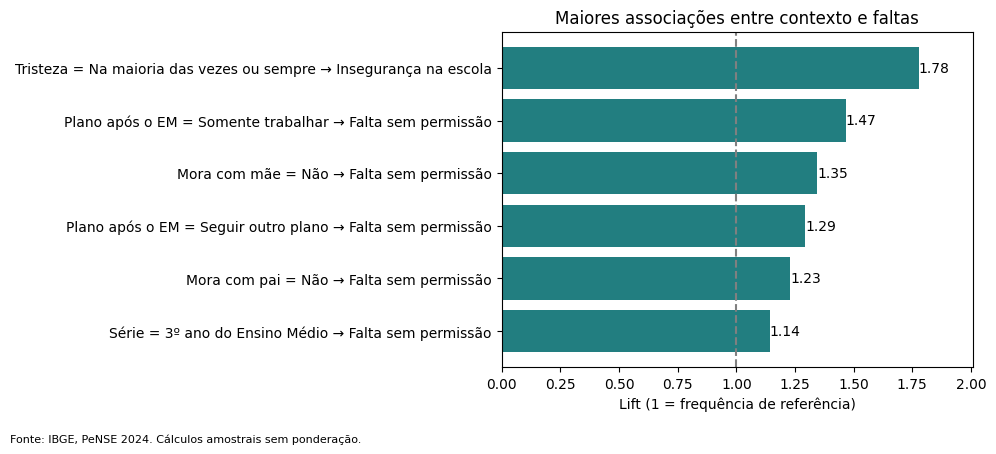

In [10]:
def apriori_pares(transacoes,suporte_minimo):
    freq1={v:transacoes[v].value_counts(normalize=True) for v in nomes}
    regras=[]
    for a,b in product([v for v in nomes if v not in alvos],sorted(alvos)):
        antecedentes=freq1[a][freq1[a]>=suporte_minimo]
        if freq1[b].get('Sim',0)<suporte_minimo:
            continue
        cont=transacoes.loc[transacoes[b].eq('Sim'),a].value_counts()
        for item,pa in antecedentes.items():
            n=int(cont.get(item,0))
            sup=n/len(transacoes)
            if sup>=suporte_minimo:
                conf=sup/pa
                regras.append([nomes[a]+' = '+str(item),nomes[b],n,sup,conf,freq1[b]['Sim'],conf/freq1[b]['Sim']])
    return pd.DataFrame(regras,columns=['antecedente','falta','n_par','suporte','confianca','base_falta','lift'])
candidatas=apriori_pares(transacoes,.01)
sens=[]
for sup,conf in product([.01,.02,.05],[.10,.20,.30]):
    selecao=candidatas.query('suporte>=@sup and confianca>=@conf and lift>=1.10')
    sens.append([sup,conf,len(selecao)])
salvar(pd.DataFrame(sens,columns=['min_suporte','min_confianca','n_regras']),'sensibilidade_apriori')
# Pelo menos 2% da amostra, probabilidade condicional ≥20% e aumento relativo ≥10%.
regras=candidatas.query('suporte>=.02 and confianca>=.20 and lift>=1.10').sort_values(['lift','suporte'],ascending=False)
salvar(regras,'regras')
print(regras.head(8).round(3).to_string(index=False))
if not regras.empty:
    top=regras.head(6).iloc[::-1]
    fig,ax=plt.subplots(figsize=(10,4.5))
    bars=ax.barh(top.antecedente+' → '+top.falta,top.lift,color='#227e80')
    ax.bar_label(bars,fmt='%.2f')
    ax.axvline(1,color='gray',linestyle='--')
    ax.set(xlabel='Lift (1 = frequência de referência)',title='Maiores associações entre contexto e faltas',xlim=(0,top.lift.max()*1.13))
    figura(fig,'regras')

## Síntese

Interpretação vinculada às tabelas desta execução. Os resultados são descritivos no domínio analisado e sem pesos amostrais.

In [11]:
print(f'Dos {len(dom):,} participantes do domínio, {len(X):,} entraram no K-Means e {len(transacoes):,} no Apriori.')
print(f'K = {k}, Silhouette = {av.silhouette.max():.3f}. A maior separação entre os grupos ocorreu em {nomes[diferenca.idxmax()]}.')
for g,row in centros.iterrows():
    v=(row-X.mean()).abs().idxmax()
    print(f'Grupo {g} (n={tamanhos[g]}): {nomes[v]} tem média escalada {row[v]:.2f}, ante {X[v].mean():.2f} no conjunto.')
if len(regras):
    r=regras.iloc[0]
    print(f'{r.antecedente}: {100*r.confianca:.1f}% relataram {r.falta.lower()}, ante {100*r.base_falta:.1f}% das transações. Lift = {r.lift:.2f}.')
print('Dados transversais e autorrelatados. Faltas e planos educacionais não medem abandono definitivo. As associações não identificam causas.')

Dos 148,736 participantes do domínio, 146,099 entraram no K-Means e 145,915 no Apriori.
K = 5, Silhouette = 0.336. A maior separação entre os grupos ocorreu em Insegurança na escola.
Grupo 1 (n=7064): Falta sem permissão tem média escalada 0.66, ante 0.07 no conjunto.
Grupo 2 (n=8308): Insegurança na escola tem média escalada 0.73, ante 0.06 no conjunto.
Grupo 3 (n=31101): Falta por saúde tem média escalada 0.69, ante 0.29 no conjunto.
Grupo 4 (n=57055): Falta por saúde tem média escalada 0.14, ante 0.29 no conjunto.
Grupo 5 (n=42571): Tristeza tem média escalada 0.17, ante 0.48 no conjunto.
Tristeza = Na maioria das vezes ou sempre: 21.4% relataram insegurança na escola, ante 12.0% das transações. Lift = 1.78.
Dados transversais e autorrelatados. Faltas e planos educacionais não medem abandono definitivo. As associações não identificam causas.
